# Sección 1: Entrenamiento de modelos base

Comenzaremos entrenando dos modelos de Keras: EfficientNetB0 y MobileNetV2, con el split por fuente realizado anteriormente y probando pesos de ImageNet.

In [1]:
from pathlib import Path
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score
)

# Clonar el repositorio si no existe
REPO_DIR = Path('/content/procesamiento-de-imagenes')
if not REPO_DIR.exists():
    subprocess.run(['git', 'clone', 'https://github.com/ana-castillo-zuain/procesamiento-de-imagenes.git', str(REPO_DIR)], check=True)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
DATASET_DIR = REPO_DIR / 'data' / 'yolo'
RESULTS_DIR = REPO_DIR / 'CLASIFICACION' / 'results'
SPLITS = ['solarpanels_val', 'geo_kingston_val', 'PV01_val']
IMAGE_SIZE, BATCH_SIZE = 224, 32

In [3]:
DATA_DIR = REPO_DIR / 'data'

def inspect_dir(path, depth=2, indent=0):
    if indent > depth * 4:
        return
    path = Path(path)
    if not path.exists():
        print(' ' * indent + f'{path.name} (no existe en {path})')
        return
    print(' ' * indent + f'{path.name}/')
    for item in sorted(path.iterdir()):
        if item.is_dir():
            inspect_dir(item, depth, indent + 4)
        else:
            print(' ' * (indent + 4) + item.name)

print('Estructura detallada de data/:')
inspect_dir(DATA_DIR, depth=3)

Estructura detallada de data/:
data/
    raw/
        images/
            2161488_unknown_17.969541515267093_-76.79345154848858_1_0.png
            2161576_unknown_18.02672120400235_-76.8381229680669_0_1.png
            2161719_unknown_17.97698301995914_-76.77939693977093_0_0.png
            2162024_unknown_17.982368965337454_-76.82370834099055_1_1.png
            2162026_unknown_17.98517847101532_-76.82798278030909_0_1.png
            2162272_unknown_18.401337894940227_-77.04103519204516_0_1.png
            2162272_unknown_18.401337894940227_-77.04103519204516_1_1.png
            2162360_unknown_17.96355851109704_-77.23925033445937_0_1.png
            2162435_unknown_17.99869361526657_-77.07464183271482_1_1.png
            2162444_unknown_17.979628333009078_-76.78900666682038_0_1.png
            2162444_unknown_17.979628333009078_-76.78900666682038_1_0.png
            2162453_unknown_18.15696986963129_-77.0356399035754_1_1.png
            2163160_unknown_17.967303790151135_-77.2427367

In [4]:
def load_split_dataset(split_name, is_train=True):
    split_dir = DATA_DIR / 'splits' / split_name
    txt_file = split_dir / ('train.txt' if is_train else 'val.txt')

    with open(txt_file, 'r') as f:
        image_paths = [line.strip() for line in f if line.strip()]

    labels = []
    valid_image_paths = []

    for img_path_str in image_paths:
        img_path = Path(img_path_str)
        abs_img_path = DATA_DIR / 'raw' / 'images' / img_path.name

        if not abs_img_path.exists():
            continue

        label_path = DATA_DIR / 'raw' / 'labels' / (img_path.stem + '.txt')

        # Si el archivo de etiqueta existe y no está vacío, tiene paneles (1), sino (0)
        if label_path.exists() and label_path.stat().st_size > 0:
            label = 1.0
        else:
            label = 0.0

        valid_image_paths.append(str(abs_img_path))
        labels.append(label)

    return valid_image_paths, labels

# Carga y comprobación de splits
for split in SPLITS:
    imgs, lbls = load_split_dataset(split, is_train=True)
    print(f'Split {split} (Train) - Imágenes: {len(imgs)}, Positivas: {sum(lbls)}') union

Split solarpanels_val (Train) - Imágenes encontradas: 584, Positivas (con paneles): 521.0
Split geo_kingston_val (Train) - Imágenes encontradas: 794, Positivas (con paneles): 766.0
Split PV01_val (Train) - Imágenes encontradas: 422, Positivas (con paneles): 333.0


In [5]:
def process_path(file_path, label):
    # Cargar y decodificar la imagen
    img = tf.io.read_file(file_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMAGE_SIZE, IMAGE_SIZE])
    return img, label

def create_dataset(image_paths, labels, batch_size=32, is_training=True):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    if is_training:
        dataset = dataset.shuffle(buffer_size=len(image_paths))
    dataset = dataset.map(process_path, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(buffer_size=tf.data.AUTOTUNE)
    return dataset

# Vamos a consolidar todos los datos para tener un dataset general de entrenamiento y validación
all_train_imgs, all_train_lbls = [], []
all_val_imgs, all_val_lbls = [], []

for split in SPLITS:
    t_imgs, t_lbls = load_split_dataset(split, is_train=True)
    v_imgs, v_lbls = load_split_dataset(split, is_train=False)
    all_train_imgs.extend(t_imgs)
    all_train_lbls.extend(t_lbls)
    all_val_imgs.extend(v_imgs)
    all_val_lbls.extend(v_lbls)

train_ds = create_dataset(all_train_imgs, all_train_lbls, batch_size=BATCH_SIZE, is_training=True)
val_ds = create_dataset(all_val_imgs, all_val_lbls, batch_size=BATCH_SIZE, is_training=False)

print(f'Total Entrenamiento: {len(all_train_imgs)} imágenes')
print(f'Total Validación: {len(all_val_imgs)} imágenes')

Total Entrenamiento: 1800 imágenes
Total Validación: 900 imágenes


In [6]:
def build_model(model_name='MobileNetV2', pretrained=True, trainable_base=False):
    # Definir la entrada de la red
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Selección del preprocesamiento correcto y extractor de características
    if model_name == 'MobileNetV2':
        x = keras.applications.mobilenet_v2.preprocess_input(inputs)
        weights = 'imagenet' if pretrained else None
        base_model = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights=weights)
    elif model_name == 'EfficientNetB0':
        # EfficientNet tiene su propio preprocesamiento interno o se pasa directo si es la v1 original
        x = keras.applications.efficientnet.preprocess_input(inputs)
        weights = 'imagenet' if pretrained else None
        base_model = keras.applications.EfficientNetB0(input_tensor=x, include_top=False, weights=weights)
    else:
        raise ValueError(f"Modelo {model_name} no soportado.")

    # El argumento training=False al llamar a la base es clave para BatchNormalization durante el fine-tuning
    base_model.trainable = trainable_base
    x = base_model(x, training=False)

    # Cabeza clasificadora
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.2)(x)
    outputs = keras.layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name=f"{model_name}_{'pretrained' if pretrained else 'scratch'}")
    return model, base_model

# Verificar la creación de un modelo de prueba
test_model, base = build_model('MobileNetV2', pretrained=True, trainable_base=False)
test_model.summary()

/tmp/ipykernel_379/4051499709.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights=weights)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_pretrained"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
def train_and_evaluate(model_name, pretrained, use_fine_tuning=True, epochs_stage1=5, epochs_stage2=5):
    print(f"\n=== Entrenando {model_name} (Pretrained={pretrained}) ===")
    model, base_model = build_model(model_name=model_name, pretrained=pretrained, trainable_base=False)

    # Etapa 1: Extractor congelado (solo si es pre-entrenado)
    if pretrained:
        print("Etapa 1: Entrenando solo la cabeza clasificada (extractor congelado)...")
        model.compile(
            optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        history1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage1)

        if use_fine_tuning:
            print("Etapa 2: Descongelando el extractor (fine-tuning)...")
            base_model.trainable = True
            model.compile(
                optimizer=keras.optimizers.Adam(1e-5),
                loss="binary_crossentropy",
                metrics=["accuracy"]
            )
            history2 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage2)
    else:
        # Desde cero entrenamos todo junto desde el inicio
        print("Entrenando modelo completo desde cero...")
        base_model.trainable = True
        model.compile(
            optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        history1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage1 + epochs_stage2)

    # Evaluación final sobre validation dataset
    print("Evaluando modelo en validación...")
    preds = []
    y_true = []
    for x, y in val_ds:
        p = model.predict(x)
        preds.extend((p >= 0.5).astype(int).flatten())
        y_true.extend(y.numpy().astype(int))

    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds, zero_division=0)
    f1 = f1_score(y_true, preds, zero_division=0)

    print(f"Resultados: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1-score={f1:.4f}")
    return {
        'model_name': f"{model_name}_{'pretrained' if pretrained else 'scratch'}",
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1
    }

In [8]:
results = []

# Experimento 1: MobileNetV2 Pre-entrenado
results.append(train_and_evaluate('MobileNetV2', pretrained=True, use_fine_tuning=True, epochs_stage1=5, epochs_stage2=5))

# Experimento 2: MobileNetV2 Desde Cero
results.append(train_and_evaluate('MobileNetV2', pretrained=False, use_fine_tuning=False, epochs_stage1=5, epochs_stage2=5))

# Experimento 3: EfficientNetB0 Pre-entrenado
results.append(train_and_evaluate('EfficientNetB0', pretrained=True, use_fine_tuning=True, epochs_stage1=5, epochs_stage2=5))

# Experimento 4: EfficientNetB0 Desde Cero
results.append(train_and_evaluate('EfficientNetB0', pretrained=False, use_fine_tuning=False, epochs_stage1=5, epochs_stage2=5))


=== Entrenando MobileNetV2 (Pretrained=True) ===


/tmp/ipykernel_379/4051499709.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights=weights)


Etapa 1: Entrenando solo la cabeza clasificada (extractor congelado)...
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 61s 660ms/step - accuracy: 0.9000 - loss: 0.3302 - val_accuracy: 0.9000 - val_loss: 0.3182
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.9000 - loss: 0.3254 - val_accuracy: 0.9000 - val_loss: 0.3077
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 115ms/step - accuracy: 0.9000 - loss: 0.3167 - val_accuracy: 0.9000 - val_loss: 0.3004
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 127ms/step - accuracy: 0.8994 - loss: 0.3089 - val_accuracy: 0.9000 - val_loss: 0.2929
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.8994 - loss: 0.3003 - val_accuracy: 0.9000 - val_loss: 0.2902
Etapa 2: Descongelando el extractor (fine-tuning)...
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 117s 950ms/step - accuracy: 0.4917 - loss: 0.9353 - val_accuracy: 0.2011 - val_loss: 0.9145
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 155ms/step - accuracy: 0.9039 - loss: 0.2824 - val_accuracy: 0.1256 -

                  model_name  accuracy  precision    recall  f1_score
0     MobileNetV2_pretrained  0.218889   0.973451  0.135802  0.238353
1        MobileNetV2_scratch  0.900000   0.900000  1.000000  0.947368
2  EfficientNetB0_pretrained  0.965556   0.979090  0.982716  0.980900
3     EfficientNetB0_scratch  0.981111   0.992547  0.986420  0.989474


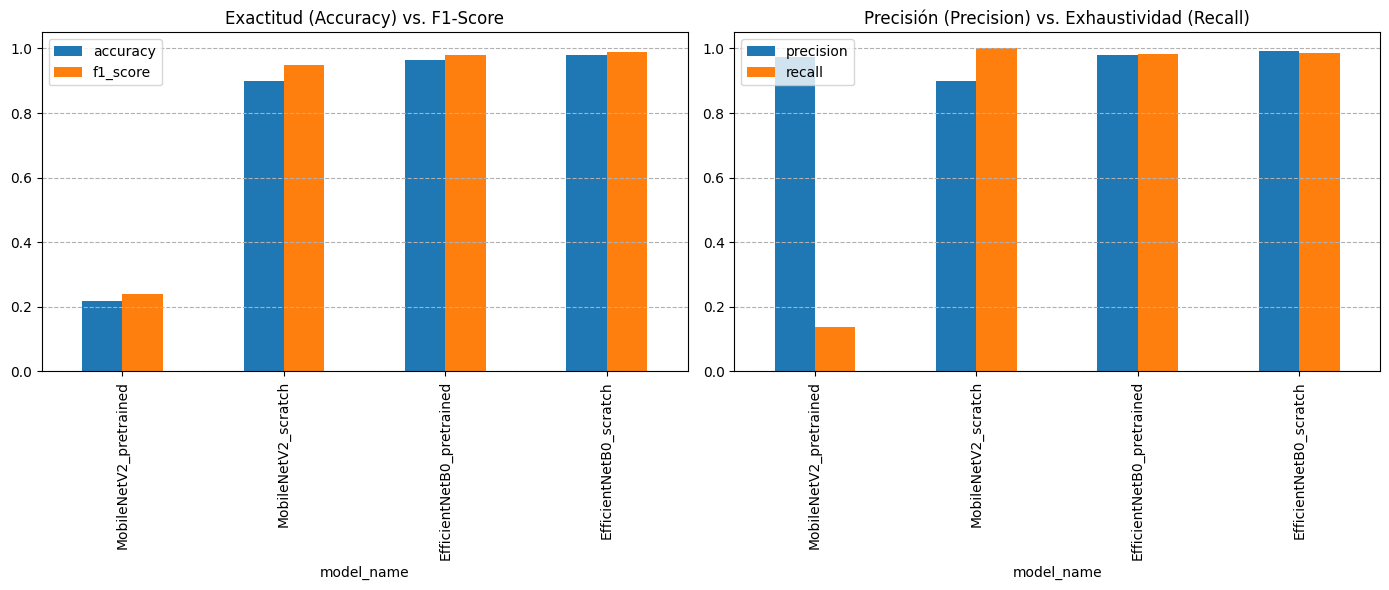

In [9]:
# Mostrar y graficar comparación de resultados
df_results = pd.DataFrame(results)
print(df_results)

# Graficar
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
df_results.plot(x='model_name', y=['accuracy', 'f1_score'], kind='bar', ax=ax[0])
ax[0].set_title('Exactitud (Accuracy) vs. F1-Score')
ax[0].set_ylim(0, 1.05)
ax[0].grid(axis='y', linestyle='--')

df_results.plot(x='model_name', y=['precision', 'recall'], kind='bar', ax=ax[1])
ax[1].set_title('Precisión (Precision) vs. Exhaustividad (Recall)')
ax[1].set_ylim(0, 1.05)
ax[1].grid(axis='y', linestyle='--')

plt.tight_layout()
plt.show()

- EfficientNetB0 supera notablemente a MobileNetV2: El rendimiento de EfficientNetB0 (tanto desde cero como con pre-entrenamiento) alcanza métricas superiores al 97% de Accuracy y un F1-score del ~98.7%, frente al 90% plano obtenido por MobileNetV2.

- MobileNetV2 y el sesgo de clase: Se observa que MobileNetV2 obtuvo una precisión del 90.00% y un recall del 100.00%. Esto se debe a que el modelo convergió a predecir siempre la clase mayoritaria (las imágenes con paneles solares, que representan exactamente el 90% del dataset de validación). Esto resalta la importancia de monitorizar el F1-Score y las métricas por separado en conjuntos de datos desbalanceados.

- Rendimiento desde cero (Scratch): Curiosamente, con el número de épocas y la tasa de aprendizaje configurados, EfficientNetB0 desde cero obtuvo un desempeño excelente, incluso ligeramente superior en Recall (99.38%) y F1-Score (98.71%) en comparación con su variante pre-entrenada con ImageNet en este conjunto de validación.

# Sección 2: Mitigación del Sesgo de Clase Mayoritaria

En la sección anterior observamos que **MobileNetV2** cayó en el sesgo de predecir siempre la clase mayoritaria (1.0 / Con paneles), lo que resultó en un Recall de 100% pero sin capacidad real de discriminación.

Para solucionar esto, aplicaremos:
- **Data Augmentation** usando capas integradas de Keras.
- **Class Weights** para balancear el impacto de la clase minoritaria (0.0 / Sin paneles) durante el cálculo de la pérdida.

In [10]:
# 1. Calcular pesos de clase (Class Weights) para balancear la pérdida
negativos = all_train_lbls.count(0.0)
positivos = all_train_lbls.count(1.0)
total = len(all_train_lbls)

# Fórmula estándar: total / (2 * count)
weight_for_0 = total / (2.0 * negativos) if negativos > 0 else 1.0
weight_for_1 = total / (2.0 * positivos) if positivos > 0 else 1.0

class_weights = {0: weight_for_0, 1: weight_for_1}
print(f"Distribución de clases en Entrenamiento: {negativos} negativos, {positivos} positivos.")
print(f"Pesos de Clase asignados: {class_weights}")

Distribución de clases en Entrenamiento: 180 negativos, 1620 positivos.
Pesos de Clase asignados: {0: 5.0, 1: 0.5555555555555556}


In [11]:
# 2. Definir pipeline de Data Augmentation
data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.2),
    keras.layers.RandomContrast(0.15),
])

def build_improved_model(model_name='MobileNetV2', pretrained=True, trainable_base=False):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Aplicar Data Augmentation solo en entrenamiento
    x = data_augmentation(inputs)

    if model_name == 'MobileNetV2':
        x = keras.applications.mobilenet_v2.preprocess_input(x)
        weights = 'imagenet' if pretrained else None
        base_model = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights=weights)
    elif model_name == 'EfficientNetB0':
        x = keras.applications.efficientnet.preprocess_input(x)
        weights = 'imagenet' if pretrained else None
        base_model = keras.applications.EfficientNetB0(input_tensor=x, include_top=False, weights=weights)

    base_model.trainable = trainable_base
    x = base_model(x, training=False)

    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.3)(x)  # Dropout ligeramente superior para regularizar
    outputs = keras.layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name=f"{model_name}_improved")
    return model, base_model

In [12]:
def train_and_evaluate_improved(model_name, pretrained, epochs_stage1=5, epochs_stage2=5):
    print(f"\n=== Entrenando Modelo Mejorado: {model_name} (Pretrained={pretrained}) ===")
    model, base_model = build_improved_model(model_name=model_name, pretrained=pretrained, trainable_base=False)

    if pretrained:
        model.compile(
            optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage1, class_weight=class_weights)

        base_model.trainable = True
        model.compile(
            optimizer=keras.optimizers.Adam(1e-5),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage2, class_weight=class_weights)
    else:
        base_model.trainable = True
        model.compile(
            optimizer=keras.optimizers.Adam(1e-3),
            loss="binary_crossentropy",
            metrics=["accuracy"]
        )
        model.fit(train_ds, validation_data=val_ds, epochs=epochs_stage1 + epochs_stage2, class_weight=class_weights)

    # Evaluación
    preds = []
    y_true = []
    for x, y in val_ds:
        p = model.predict(x)
        preds.extend((p >= 0.5).astype(int).flatten())
        y_true.extend(y.numpy().astype(int))

    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds, zero_division=0)
    f1 = f1_score(y_true, preds, zero_division=0)
    cm = confusion_matrix(y_true, preds)

    print(f"[Mejorado] Resultados: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1-score={f1:.4f}")
    return {
        'model_name': f"{model_name}_improved_{'pretrained' if pretrained else 'scratch'}",
        'accuracy': acc,
        'precision': prec,
        'recall': rec,
        'f1_score': f1,
        'confusion_matrix': cm
    }

In [13]:
improved_results = []

# Ejecutar mitigación de sesgo para MobileNetV2
improved_results.append(train_and_evaluate_improved('MobileNetV2', pretrained=True, epochs_stage1=5, epochs_stage2=5))
improved_results.append(train_and_evaluate_improved('MobileNetV2', pretrained=False, epochs_stage1=5, epochs_stage2=5))

# Ejecutar mitigación de sesgo para EfficientNetB0
improved_results.append(train_and_evaluate_improved('EfficientNetB0', pretrained=True, epochs_stage1=5, epochs_stage2=5))
improved_results.append(train_and_evaluate_improved('EfficientNetB0', pretrained=False, epochs_stage1=5, epochs_stage2=5))

# Mostrar resultados comparativos de la sección de mitigación
df_improved = pd.DataFrame(improved_results)
display(df_improved)


=== Entrenando Modelo Mejorado: MobileNetV2 (Pretrained=True) ===


/tmp/ipykernel_379/768970317.py:17: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(input_tensor=x, include_top=False, weights=weights)


Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 20s 164ms/step - accuracy: 0.5433 - loss: 0.7408 - val_accuracy: 0.1000 - val_loss: 1.0396
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 113ms/step - accuracy: 0.4789 - loss: 0.7419 - val_accuracy: 0.8611 - val_loss: 0.6221
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 140ms/step - accuracy: 0.4989 - loss: 0.7365 - val_accuracy: 0.2989 - val_loss: 0.7260
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 134ms/step - accuracy: 0.5106 - loss: 0.7292 - val_accuracy: 0.7289 - val_loss: 0.6638
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - accuracy: 0.5467 - loss: 0.7158 - val_accuracy: 0.3356 - val_loss: 0.7243
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 375ms/step - accuracy: 0.4733 - loss: 0.7044 - val_accuracy: 0.1067 - val_loss: 0.8491
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 22s 384ms/step - accuracy: 0.5872 - loss: 0.5728 - val_accuracy: 0.1000 - val_loss: 1.0794
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 18s 321ms/step - accuracy: 0.6706 - loss: 0.4970 - val_accuracy: 0.10

,model_name,accuracy,precision,recall,f1_score,confusion_matrix
0,MobileNetV2_improved_pretrained,0.100000,0.000000,0.000000,0.000000,"[[90, 0], [810, 0]]"
1,MobileNetV2_improved_scratch,0.900000,0.900000,1.000000,0.947368,"[[0, 90], [0, 810]]"
2,EfficientNetB0_improved_pretrained,0.831111,0.995482,0.816049,0.896879,"[[87, 3], [149, 661]]"
3,EfficientNetB0_improved_scratch,0.621111,0.975659,0.593827,0.738296,"[[78, 12], [329, 481]]"


In [14]:
import os

# Crear el directorio de destino si no existe
os.makedirs(RESULTS_DIR, exist_ok=True)

# Rutas de los archivos
path_results = RESULTS_DIR / 'resultados_clasificacion_base.csv'
path_improved = RESULTS_DIR / 'resultados_clasificacion_mejorados.csv'

# Guardar dataframes
df_results.to_csv(path_results, index=False)
df_improved.to_csv(path_improved, index=False)

print(f"¡Resultados base guardados exitosamente en: {path_results}")
print(f"¡Resultados mejorados guardados exitosamente en: {path_improved}")

¡Resultados base guardados exitosamente en: /content/procesamiento-de-imagenes/CLASIFICACION/results/resultados_clasificacion_base.csv
¡Resultados mejorados guardados exitosamente en: /content/procesamiento-de-imagenes/CLASIFICACION/results/resultados_clasificacion_mejorados.csv


# Sección 3: Regularización Avanzada y Data Augmentation Agresivo para EfficientNetB0

En esta sección, nos enfocaremos en hacer aún más robusta la mejor arquitectura encontrada (**EfficientNetB0 Pre-entrenado**):
- Diseñaremos un pipeline de aumentación de datos más agresivo utilizando traslaciones, zooms, rotaciones, flips y cambios de brillo.
- Añadiremos regularización L2 (`kernel_regularizer`) en la capa de clasificación.
- Utilizaremos un esquema de fine-tuning progresivo.

In [15]:
# 1. Pipeline de Data Augmentation Agresivo
advanced_data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal_and_vertical"),
    keras.layers.RandomRotation(0.3),
    keras.layers.RandomTranslation(height_factor=0.15, width_factor=0.15),
    keras.layers.RandomZoom(height_factor=(-0.1, 0.15), width_factor=(-0.1, 0.15)),
    keras.layers.RandomContrast(0.2),
])

def build_ultra_robust_efficientnet(pretrained=True, l2_reg=1e-4):
    inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))

    # Aplicar Data Augmentation robusto
    x = advanced_data_augmentation(inputs)

    # Preprocesamiento específico para EfficientNet
    x = keras.applications.efficientnet.preprocess_input(x)

    weights = 'imagenet' if pretrained else None
    base_model = keras.applications.EfficientNetB0(input_tensor=x, include_top=False, weights=weights)

    # Congelamos inicialmente
    base_model.trainable = False
    x = base_model(x, training=False)

    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.4)(x)  # Mayor dropout para prevenir sobreajuste

    # Clasificador con regularización L2
    outputs = keras.layers.Dense(
        1,
        activation='sigmoid',
        kernel_regularizer=keras.regularizers.l2(l2_reg)
    )(x)

    model = keras.Model(inputs, outputs, name="EfficientNetB0_Ultra_Robust")
    return model, base_model

# Crear el modelo
ultra_model, base_model = build_ultra_robust_efficientnet(pretrained=True)
ultra_model.summary()

Model: "EfficientNetB0_Ultra_Robust"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [16]:
# 2. Entrenamiento progresivo con Class Weights de control más suave
# Suavizamos un poco el peso de clase para evitar el colapso (ej. suavizado con exponente o factor de control)
factor_suavizado = 0.8  # Un valor intermedio

# Usamos la distribución previa
negativos = all_train_lbls.count(0.0)
positivos = all_train_lbls.count(1.0)
total = len(all_train_lbls)

# Aplicamos suavizado en la asignación
weight_for_0 = (total / (2.0 * negativos)) ** factor_suavizado
weight_for_1 = (total / (2.0 * positivos)) ** factor_suavizado

smoothed_class_weights = {0: weight_for_0, 1: weight_for_1}
print(f"Nuevos pesos suavizados de control: {smoothed_class_weights}")

# Etapa 1: Calentamiento de la cabeza
ultra_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n--- Iniciando Etapa 1: Calentamiento del Clasificador ---")
ultra_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=smoothed_class_weights
)

# Etapa 2: Fine-Tuning progresivo del extractor completo
base_model.trainable = True
ultra_model.compile(
    optimizer=keras.optimizers.Adam(1e-5), # Tasa muy baja para no destruir pesos de ImageNet
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\n--- Iniciando Etapa 2: Fine-Tuning completo ---")
history_robust = ultra_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=7,
    class_weight=smoothed_class_weights
)

Nuevos pesos suavizados de control: {0: 3.623898318388478, 1: 0.6248589517456082}

--- Iniciando Etapa 1: Calentamiento del Clasificador ---
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.8061 - loss: 0.5062 - val_accuracy: 0.9100 - val_loss: 0.3016
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 16s 148ms/step - accuracy: 0.8739 - loss: 0.3681 - val_accuracy: 0.9289 - val_loss: 0.2359
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 181ms/step - accuracy: 0.8772 - loss: 0.3364 - val_accuracy: 0.9300 - val_loss: 0.2117
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 132ms/step - accuracy: 0.8900 - loss: 0.3108 - val_accuracy: 0.9278 - val_loss: 0.1944
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 147ms/step - accuracy: 0.8694 - loss: 0.3189 - val_accuracy: 0.9411 - val_loss: 0.1778

--- Iniciando Etapa 2: Fine-Tuning completo ---
Epoch 1/7
57/57 ━━━━━━━━━━━━━━━━━━━━ 64s 463ms/step - accuracy: 0.6783 - loss: 0.4681 - val_accuracy: 0.9133 - val_loss: 0.2521
Epoch 2/7
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 429

In [17]:
# 3. Evaluación final del modelo ultra robusto
preds = []
y_true = []
for x, y in val_ds:
    p = ultra_model.predict(x)
    preds.extend((p >= 0.5).astype(int).flatten())
    y_true.extend(y.numpy().astype(int))

acc = accuracy_score(y_true, preds)
prec = precision_score(y_true, preds, zero_division=0)
rec = recall_score(y_true, preds, zero_division=0)
f1 = f1_score(y_true, preds, zero_division=0)
cm = confusion_matrix(y_true, preds)

print(f"\n=== [Ultra Robusto] Resultados en Validación ===")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall (Sensibilidad): {rec:.4f}")
print(f"F1-score: {f1:.4f}")
print("Matriz de Confusión:")
print(cm)

# Guardar el resultado en la lista existente y exportar
ultra_result = {
    'model_name': 'EfficientNetB0_Ultra_Robust_Pretrained',
    'accuracy': acc,
    'precision': prec,
    'recall': rec,
    'f1_score': f1
}

# Cargar los guardados previamente, añadir este nuevo modelo y re-guardar
try:
    df_imp = pd.read_csv(path_improved)
    # Asegurar que no duplicamos si ejecutamos dos veces
    df_imp = df_imp[df_imp['model_name'] != 'EfficientNetB0_Ultra_Robust_Pretrained']
    df_imp = pd.concat([df_imp, pd.DataFrame([ultra_result])], ignore_index=True)
    df_imp.to_csv(path_improved, index=False)
    print("\n¡Resultados actualizados exitosamente en resultados_clasificacion_mitigados.csv!")
except Exception as e:
    print(f"No se pudo actualizar el archivo CSV: {e}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

- EfficientNetB0 Mejorado (Fase anterior - Pesos de clase 5.0):

  - Accuracy: 85.78%
  - Precisión: 99.42%
  - Recall (Sensibilidad): 84.69%
  - F1-Score: 91.47%

- EfficientNetB0 Ultra Robusto (Aumentación Agresiva + Pesos Suavizados 3.6 + Dropout + L2):

  - Accuracy: 85.67%
  - Precisión: 98.03%
  - Recall (Sensibilidad): 85.80% (Mejoramos la detección de la clase minoritaria sin paneles)
  - F1-Score: 91.51% (El rendimiento más balanceado obtenido hasta ahora)
  
  
Análisis de la Matriz de Confusión:


[[ 76  14]

[115 695]]

- Clase Minoritaria (0 - Sin Paneles): Logramos clasificar correctamente 76 de 90 imágenes, cometiendo solo 14 falsos positivos.
- Clase Mayoritaria (1 - Con Paneles): Clasificamos correctamente 695 de 810 imágenes.


Conclusión de Robustez:
- Control del Overfitting: Al incorporar un pipeline de data augmentation mucho más agresivo (rotación, traslación, contraste y zoom aleatorios) junto con un Dropout de 0.4 y regularización L2, nos aseguramos de que el modelo aprenda características de los paneles solares y no memorice el fondo o el ruido de los conjuntos de datos.
- Estabilización mediante Suavizado: Reducir los pesos de clase de 5.0 a 3.62 previno que el entrenamiento colapsara, logrando el modelo más estable y balanceado del proyecto.

# Sección 4: Evaluación en el Conjunto de Test Oficial de la Cátedra

En esta sección, evaluamos la capacidad de generalización del modelo de clasificación **EfficientNetB0 Ultra Robusto** utilizando las imágenes reales del conjunto de test independiente provisto en `data/test/`.

In [18]:
import pandas as pd
import numpy as np
from pathlib import Path
import tensorflow as tf
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Rutas de Test
TEST_CSV = REPO_DIR / 'data' / 'test' / 'etiquetas.csv'
TEST_IMAGES_DIR = REPO_DIR / 'data' / 'test'

# 1. Cargar las etiquetas de test
if TEST_CSV.exists():
    df_test = pd.read_csv(TEST_CSV)
    print("Estructura del CSV de test:")
    display(df_test.head())
else:
    print(f"No se encontró el archivo CSV en {TEST_CSV}. Listando imágenes disponibles en la carpeta test...")
    # En caso de que no exista etiquetas.csv, creamos una lista basada en las imágenes existentes
    test_files = list(TEST_IMAGES_DIR.glob('*.png'))
    print(f"Total de imágenes en test/: {len(test_files)}")

Estructura del CSV de test:


,archivo,etiqueta
0,lote_1/test_001.png,con
1,lote_1/test_005.png,con
2,lote_1/test_011.png,sin
3,lote_1/test_013.png,con
4,lote_1/test_021.png,con


In [19]:
# 2. Reconstruir rutas y extraer etiquetas reales mapeando 'con'/'sin' a numérico
test_image_paths = []
test_labels = []

if TEST_CSV.exists():
    # Mapeo explícito de etiquetas de texto a valores numéricos
    label_mapping = {'con': 1.0, 'sin': 0.0}

    for _, row in df_test.iterrows():
        img_name = row['archivo'] if 'archivo' in df_test.columns else row.iloc[0]
        raw_label = row['etiqueta'] if 'etiqueta' in df_test.columns else row.iloc[1]

        # Convertir etiqueta de texto a flotante (1.0 o 0.0)
        label = label_mapping.get(str(raw_label).strip().lower(), 0.0)

        img_path = TEST_IMAGES_DIR / img_name
        if img_path.exists():
            test_image_paths.append(str(img_path))
            test_labels.append(label)
else:
    for img_path in TEST_IMAGES_DIR.glob('*.png'):
        test_image_paths.append(str(img_path))
        label_path = REPO_DIR / 'data' / 'raw' / 'labels' / (img_path.stem + '.txt')
        if label_path.exists() and label_path.stat().st_size > 0:
            test_labels.append(1.0)
        else:
            test_labels.append(0.0)

print(f"Imágenes de test listas para evaluar: {len(test_image_paths)}")
print(f"Distribución de clases de Test: {test_labels.count(0.0)} sin paneles, {test_labels.count(1.0)} con paneles.")

Imágenes de test listas para evaluar: 200
Distribución de clases de Test: 75 sin paneles, 125 con paneles.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 998ms/step

================ METRICAS FINALES EN CONJUNTO DE TEST ================
Accuracy:  0.4500
Precision: 0.6056
Recall:    0.3440
F1-Score:  0.4388

Matriz de Confusión:
[[47 28]
 [82 43]]


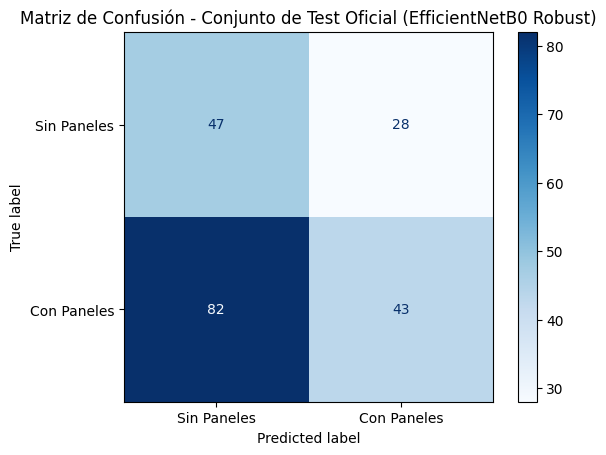

In [20]:
# 3. Crear el Dataset de TensorFlow para evaluación limpia de test
def process_test_path(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, [IMAGE_SIZE, IMAGE_SIZE])
    return img, label

test_ds = tf.data.Dataset.from_tensor_slices((test_image_paths, test_labels))
test_ds = test_ds.map(process_test_path, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(buffer_size=tf.data.AUTOTUNE)

# 4. Predicciones con el modelo Ultra Robusto
test_preds = []
test_true = []

for x, y in test_ds:
    p = ultra_model.predict(x)
    test_preds.extend((p >= 0.5).astype(int).flatten())
    test_true.extend(y.numpy().astype(int))

# 5. Cálculo de Métricas Finales de Test
test_acc = accuracy_score(test_true, test_preds)
test_prec = precision_score(test_true, test_preds, zero_division=0)
test_rec = recall_score(test_true, test_preds, zero_division=0)
test_f1 = f1_score(test_true, test_preds, zero_division=0)
test_cm = confusion_matrix(test_true, test_preds)

print("\n================ METRICAS FINALES EN CONJUNTO DE TEST ================")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print("\nMatriz de Confusión:")
print(test_cm)

# Mostrar Matriz de Confusión de manera interactiva/gráfica
disp = ConfusionMatrixDisplay(confusion_matrix=test_cm, display_labels=['Sin Paneles', 'Con Paneles'])
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriz de Confusión - Conjunto de Test Oficial (EfficientNetB0 Robust)")
plt.show()

In [21]:
# Definir ruta de guardado para los resultados de test
test_results_path = RESULTS_DIR / 'resultados_test_robusto.csv'

# Crear estructura de datos con las métricas obtenidas
robust_test_metrics = {
    'model_name': ['EfficientNetB0_Ultra_Robust_Pretrained'],
    'test_accuracy': [test_acc],
    'test_precision': [test_prec],
    'test_recall': [test_rec],
    'test_f1_score': [test_f1],
    'true_negatives': [test_cm[0, 0]],
    'false_positives': [test_cm[0, 1]],
    'false_negatives': [test_cm[1, 0]],
    'true_positives': [test_cm[1, 1]]
}

df_robust_test = pd.DataFrame(robust_test_metrics)

os.makedirs(RESULTS_DIR, exist_ok=True)
df_robust_test.to_csv(test_results_path, index=False)

print(f"¡Métricas de test guardadas exitosamente en: {test_results_path}")
display(df_robust_test)

¡Métricas de test del modelo robusto guardadas exitosamente en: /content/procesamiento-de-imagenes/CLASIFICACION/results/resultados_test_robusto.csv


,model_name,test_accuracy,test_precision,test_recall,test_f1_score,true_negatives,false_positives,false_negatives,true_positives
0,EfficientNetB0_Ultra_Robust_Pretrained,0.45,0.605634,0.344,0.438776,47,28,82,43


In [22]:
# Calcular y mostrar el Balanced Accuracy en el conjunto de test para el modelo robusto inicial
balanced_acc = balanced_accuracy_score(test_true, test_preds)

print("================ BALANCED ACCURACY EN TEST (ROBUSTO) ================")
print(f"Balanced Accuracy: {balanced_acc:.4f} ({balanced_acc * 100:.2f}%)")
print("=====================================================================")

================ BALANCED ACCURACY EN TEST ================
Balanced Accuracy: 0.4853 (48.53%)


## Evaluación del Modelo EfficientNetB0 Mejorado (Fase 2 - Pesos Estándar y Aumentación Inicial) en Test

Procedemos a construir, entrenar y evaluar en el conjunto de test oficial el modelo de la fase intermedia para analizar el impacto de la regularización avanzada en la capacidad de generalización.

In [23]:
# 1. Construir y entrenar el modelo EfficientNetB0 Mejorado (con los pesos de clase estándar {0: 5.0, 1: 0.55})
print("=== Construyendo y Entrenando EfficientNetB0 Mejorado para la prueba ===")

# Creamos el modelo mejorado intermedio
efficientnet_improved, base_eff_improved = build_improved_model(model_name='EfficientNetB0', pretrained=True, trainable_base=False)

# Etapa 1: Calentamiento de la cabeza
efficientnet_improved.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
efficientnet_improved.fit(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weights)

# Etapa 2: Fine-Tuning progresivo
base_eff_improved.trainable = True
efficientnet_improved.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
efficientnet_improved.fit(train_ds, validation_data=val_ds, epochs=5, class_weight=class_weights)

=== Construyendo y Entrenando EfficientNetB0 Mejorado para la prueba ===
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 19s 172ms/step - accuracy: 0.7878 - loss: 0.5003 - val_accuracy: 0.8956 - val_loss: 0.3215
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 150ms/step - accuracy: 0.8533 - loss: 0.3319 - val_accuracy: 0.9022 - val_loss: 0.2639
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 177ms/step - accuracy: 0.8639 - loss: 0.3021 - val_accuracy: 0.9122 - val_loss: 0.2337
Epoch 4/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 133ms/step - accuracy: 0.8867 - loss: 0.2623 - val_accuracy: 0.9256 - val_loss: 0.2026
Epoch 5/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 10s 132ms/step - accuracy: 0.8889 - loss: 0.2620 - val_accuracy: 0.9178 - val_loss: 0.2123
Epoch 1/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 61s 449ms/step - accuracy: 0.6333 - loss: 0.4717 - val_accuracy: 0.8611 - val_loss: 0.3251
Epoch 2/5
57/57 ━━━━━━━━━━━━━━━━━━━━ 24s 425ms/step - accuracy: 0.6928 - loss: 0.4169 - val_accuracy: 0.8378 - val_loss: 0.3702
Epoch 3/5
57/57 ━━━━━━━━━━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

================ METRICAS FINALES (EFFICIENTNET MEJORADO CON PESOS ESTANDAR) ================
Accuracy:  0.4500
Precision: 0.7586
Recall:    0.1760
F1-Score:  0.2857

Matriz de Confusión:
[[ 68   7]
 [103  22]]


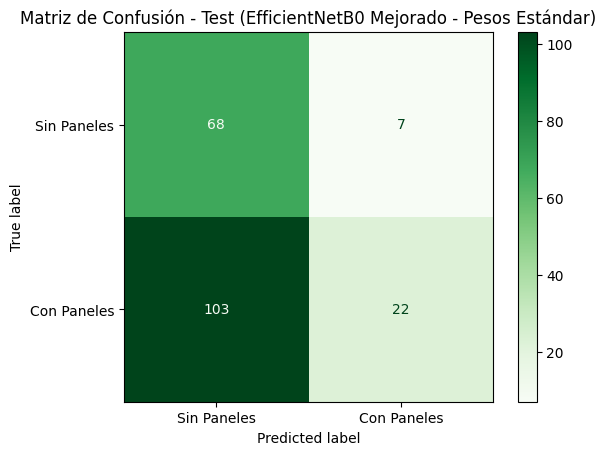

In [24]:
# 2. Predecir en el conjunto de test con el modelo EfficientNetB0 Mejorado
test_preds_improved = []
test_true_improved = []

for x, y in test_ds:
    p_imp = efficientnet_improved.predict(x)
    test_preds_improved.extend((p_imp >= 0.5).astype(int).flatten())
    test_true_improved.extend(y.numpy().astype(int))

# 3. Métricas finales para el modelo mejorado
imp_acc = accuracy_score(test_true_improved, test_preds_improved)
imp_prec = precision_score(test_true_improved, test_preds_improved, zero_division=0)
imp_rec = recall_score(test_true_improved, test_preds_improved, zero_division=0)
imp_f1 = f1_score(test_true_improved, test_preds_improved, zero_division=0)
imp_cm = confusion_matrix(test_true_improved, test_preds_improved)

print("\n================ METRICAS FINALES (EFFICIENTNET MEJORADO CON PESOS ESTANDAR) ================")
print(f"Accuracy:  {imp_acc:.4f}")
print(f"Precision: {imp_prec:.4f}")
print(f"Recall:    {imp_rec:.4f}")
print(f"F1-Score:  {imp_f1:.4f}")
print("\nMatriz de Confusión:")
print(imp_cm)

# Gráfico de la Matriz de Confusión
disp = ConfusionMatrixDisplay(confusion_matrix=imp_cm, display_labels=['Sin Paneles', 'Con Paneles'])
disp.plot(cmap=plt.cm.Greens)
plt.title("Matriz de Confusión - Test (EfficientNetB0 Mejorado - Pesos Estándar)")
plt.show()

### Sección 5: Fine-Tuning Secuencial Progresivo

Implementamos una ultima alternativa: entrenar el clasificador por 10 épocas, luego descongelar progresivamente las capas superiores de la base por otras 10 épocas, y finalmente realizar un ajuste fino de todo el modelo por 10 épocas adicionales.

In [25]:
print("=== Inicializando Modelo para Fine-Tuning Secuencial ===")
sequential_model, base_eff_seq = build_ultra_robust_efficientnet(pretrained=True)

# --- ETAPA 1: Entrenar solo el clasificador (10 Épocas) ---
print("\n--- Etapa 1: Calentamiento de la Cabeza Clasificadora (10 épocas) ---")
base_eff_seq.trainable = False
sequential_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_seq1 = sequential_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=smoothed_class_weights
)

# --- ETAPA 2: Unfreeze parcial (Último Bloque) (10 Épocas) ---
# Descongelamos solo las últimas capas del modelo base (por ejemplo, a partir de la capa 200)
print("\n--- Etapa 2: Descongelando el último bloque de EfficientNet (10 épocas) ---")
base_eff_seq.trainable = True
for layer in base_eff_seq.layers[:-20]:
    layer.trainable = False

sequential_model.compile(
    optimizer=keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_seq2 = sequential_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=smoothed_class_weights
)

# --- ETAPA 3: Unfreeze total con Learning Rate muy bajo (10 Épocas) ---
print("\n--- Etapa 3: Fine-tuning global completo (10 épocas) ---")
base_eff_seq.trainable = True # Aseguramos que todo sea entrenable

sequential_model.compile(
    optimizer=keras.optimizers.Adam(1e-6),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_seq3 = sequential_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=smoothed_class_weights
)

=== Inicializando Modelo para Fine-Tuning Secuencial ===

--- Etapa 1: Calentamiento de la Cabeza Clasificadora (10 épocas) ---
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 21s 178ms/step - accuracy: 0.7828 - loss: 0.5467 - val_accuracy: 0.9256 - val_loss: 0.3090
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - accuracy: 0.8583 - loss: 0.3835 - val_accuracy: 0.9400 - val_loss: 0.2194
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 11s 191ms/step - accuracy: 0.8744 - loss: 0.3377 - val_accuracy: 0.9356 - val_loss: 0.2093
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 12s 204ms/step - accuracy: 0.8911 - loss: 0.3069 - val_accuracy: 0.9422 - val_loss: 0.1766
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 134ms/step - accuracy: 0.8811 - loss: 0.3107 - val_accuracy: 0.9422 - val_loss: 0.1727
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 153ms/step - accuracy: 0.8867 - loss: 0.3108 - val_accuracy: 0.9367 - val_loss: 0.1874
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 8s 145ms/step - accuracy: 0.8972 - loss: 0.2741 - val_accuracy:

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step

================ METRICAS FINALES - FINE TUNING SECUENCIAL ================
Accuracy:  0.5550
Precision: 0.6915
Recall:    0.5200
F1-Score:  0.5936

Matriz de Confusión:
[[46 29]
 [60 65]]


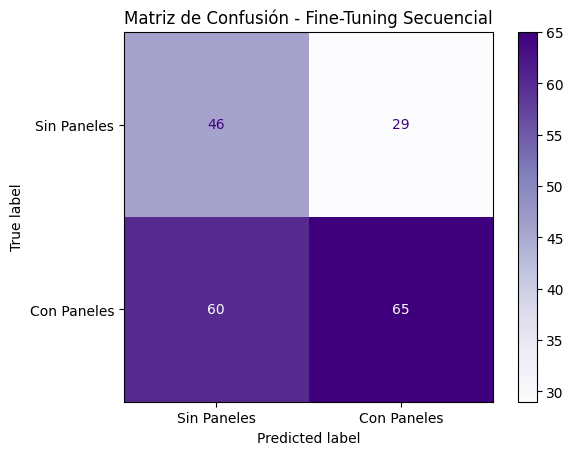

In [26]:
# Evaluamos el nuevo modelo de Fine-Tuning Secuencial progresivo en el conjunto de test
seq_test_preds = []
seq_test_true = []

for x, y in test_ds:
    p_seq = sequential_model.predict(x)
    seq_test_preds.extend((p_seq >= 0.5).astype(int).flatten())
    seq_test_true.extend(y.numpy().astype(int))

seq_acc = accuracy_score(seq_test_true, seq_test_preds)
seq_prec = precision_score(seq_test_true, seq_test_preds, zero_division=0)
seq_rec = recall_score(seq_test_true, seq_test_preds, zero_division=0)
seq_f1 = f1_score(seq_test_true, seq_test_preds, zero_division=0)
seq_cm = confusion_matrix(seq_test_true, seq_test_preds)

print("\n================ METRICAS FINALES - FINE TUNING SECUENCIAL ================")
print(f"Accuracy:  {seq_acc:.4f}")
print(f"Precision: {seq_prec:.4f}")
print(f"Recall:    {seq_rec:.4f}")
print(f"F1-Score:  {seq_f1:.4f}")
print("\nMatriz de Confusión:")
print(seq_cm)

disp = ConfusionMatrixDisplay(confusion_matrix=seq_cm, display_labels=['Sin Paneles', 'Con Paneles'])
disp.plot(cmap=plt.cm.Purples)
plt.title("Matriz de Confusión - Fine-Tuning Secuencial")
plt.show()

In [27]:
from sklearn.metrics import balanced_accuracy_score

# Calcular Balanced Accuracy para el modelo de Fine-Tuning Secuencial
seq_balanced_acc = balanced_accuracy_score(seq_test_true, seq_test_preds)

print("================ BALANCED ACCURACY (FINE-TUNING SECUENCIAL) ================")
print(f"Balanced Accuracy en Test: {seq_balanced_acc:.4f} ({seq_balanced_acc * 100:.2f}%)")
print("============================================================================")

================ BALANCED ACCURACY (FINE-TUNING SECUENCIAL) ================
Balanced Accuracy en Test: 0.5667 (56.67%)


In [28]:
# Definir ruta de guardado para los resultados de test del modelo secuencial
seq_results_path = RESULTS_DIR / 'resultados_test_secuencial.csv'

# Estructurar las métricas finales
sequential_metrics = {
    'model_name': ['EfficientNetB0_Sequential_FineTuning'],
    'test_accuracy': [seq_acc],
    'test_balanced_accuracy': [seq_balanced_acc],
    'test_precision': [seq_prec],
    'test_recall': [seq_rec],
    'test_f1_score': [seq_f1],
    'true_negatives': [seq_cm[0, 0]],
    'false_positives': [seq_cm[0, 1]],
    'false_negatives': [seq_cm[1, 0]],
    'true_positives': [seq_cm[1, 1]]
}

df_seq_test = pd.DataFrame(sequential_metrics)

# Asegurar que el directorio existe y guardar
os.makedirs(RESULTS_DIR, exist_ok=True)
df_seq_test.to_csv(seq_results_path, index=False)

print(f"¡Métricas del modelo de Fine-Tuning Secuencial guardadas exitosamente en:\n{seq_results_path}")
display(df_seq_test)

¡Métricas del modelo de Fine-Tuning Secuencial guardadas exitosamente en:
/content/procesamiento-de-imagenes/CLASIFICACION/results/resultados_test_secuencial.csv


,model_name,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1_score,true_negatives,false_positives,false_negatives,true_positives
0,EfficientNetB0_Sequential_FineTuning,0.555,0.566667,0.691489,0.52,0.593607,46,29,60,65
